In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
url = "https://huggingface.co/datasets/abhinavsarkar/delhi_air_quality_feature_store_processed.csv/resolve/main/delhi_air_quality_feature_store_processed.csv"

data = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows and Columns:", data.shape)

Rows and Columns: (2921413, 15)


In [ ]:
data.head()

,location_id,city,event_timestamp,temperature,humidity,pressure,wind_speed,wind_direction,pm25,pm10,no2,so2,o3,co,aqi
0,"Delhi Institute of Tool Engineering, Wazirpur,...",Wazirpur,2000-03-15 13:44:28.651396,30.450,74.100,990.425,0.300,21.7,252.0,332.0,62.4,4.8,22.4,35.7,332.0
1,"Satyawati College, Delhi, Delhi, India",Delhi,2000-03-15 13:44:28.651396,26.675,74.350,980.650,1.375,55.3,256.0,234.0,59.2,11.9,2.1,33.8,256.0
2,"ITI Shahdra, Jhilmil Industrial Area, Delhi, D...",Jhilmil,2000-03-15 13:44:28.651396,28.775,62.925,984.350,0.300,221.3,265.0,210.0,48.3,5.1,8.2,35.1,265.0
3,"Sonia Vihar Water Treatment Plant DJB, Delhi, ...",Sonia Vihar,2000-03-15 13:44:28.651396,26.575,78.525,991.300,0.300,313.6,251.0,177.0,16.5,1.8,1.7,24.9,251.0
4,"PGDAV College, Sriniwaspuri, Delhi, Delhi, India",Sriniwaspuri,2000-03-15 13:44:28.651396,22.300,71.425,985.650,0.300,347.1,282.0,347.0,43.1,5.2,3.4,29.9,347.0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2921413 entries, 0 to 2921412
Data columns (total 15 columns):
 #   Column           Dtype  
---  ------           -----  
 0   location_id      object 
 1   city             object 
 2   event_timestamp  object 
 3   temperature      float64
 4   humidity         float64
 5   pressure         float64
 6   wind_speed       float64
 7   wind_direction   float64
 8   pm25             float64
 9   pm10             float64
 10  no2              float64
 11  so2              float64
 12  o3               float64
 13  co               float64
 14  aqi              float64
dtypes: float64(12), object(3)
memory usage: 334.3+ MB


In [ ]:
data.columns

Index(['location_id', 'city', 'event_timestamp', 'temperature', 'humidity',
       'pressure', 'wind_speed', 'wind_direction', 'pm25', 'pm10', 'no2',
       'so2', 'o3', 'co', 'aqi'],
      dtype='object')

In [ ]:
data.isnull().sum()

,0
location_id,0
city,0
event_timestamp,0
temperature,0
humidity,0
pressure,0
wind_speed,0
wind_direction,0
pm25,0
pm10,0


In [ ]:
data.isnull().sum().sum()

np.int64(0)

In [ ]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 3


In [ ]:
features = [
    'pm25',
    'pm10',
    'no2',
    'so2',
    'o3',
    'co',
    'temperature',
    'humidity',
    'pressure',
    'wind_speed'
]

target = 'aqi'

In [ ]:
data_model = data[features + [target]].copy()

In [ ]:
data_model = data_model.dropna()

print("Dataset shape after preprocessing:", data_model.shape)

Dataset shape after preprocessing: (2921413, 11)


In [ ]:
data_model.isnull().sum()

,0
pm25,0
pm10,0
no2,0
so2,0
o3,0
co,0
temperature,0
humidity,0
pressure,0
wind_speed,0


In [ ]:
data_model.describe()

,pm25,pm10,no2,so2,o3,co,temperature,humidity,pressure,wind_speed,aqi
count,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06,2.921413e+06
mean,2.428436e+02,2.525172e+02,2.742289e+01,6.990574e+00,2.870380e+01,1.887028e+01,2.967448e+01,5.972461e+01,9.839373e+02,5.755100e-01,2.846162e+02
std,6.004317e+01,1.442264e+02,1.745550e+01,3.724060e+00,3.025712e+01,1.545748e+01,3.519299e+00,1.742223e+01,6.239824e+00,4.821382e-01,1.280330e+02
min,1.700000e+02,1.090000e+02,3.700000e+00,2.000000e-01,5.000000e-01,1.000000e-01,2.050000e+01,3.830000e+01,9.647500e+02,1.000000e-01,1.430000e+02
25%,1.950000e+02,1.610000e+02,1.510000e+01,3.800000e+00,4.400000e+00,8.200000e+00,2.710000e+01,4.400000e+01,9.805000e+02,3.000000e-01,2.000000e+02
50%,2.270000e+02,1.900000e+02,2.540000e+01,7.500000e+00,1.780000e+01,1.380000e+01,3.007500e+01,5.260000e+01,9.846850e+02,3.000000e-01,2.430000e+02
75%,2.740000e+02,3.240000e+02,3.470000e+01,9.500000e+00,3.530000e+01,2.840000e+01,3.269100e+01,7.602500e+01,9.878000e+02,6.750000e-01,3.250000e+02
max,4.670000e+02,9.300000e+02,9.080000e+01,2.020000e+01,1.178000e+02,6.930000e+01,3.575000e+01,9.400000e+01,9.964000e+02,3.300000e+00,9.300000e+02


In [ ]:
data_model = data_model.sample(
    n=100000,
    random_state=42
)

print(data_model.shape)

(100000, 11)


In [ ]:
X = data_model[features]
y = data_model[target]

In [ ]:
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
          pm25   pm10   no2  so2    o3    co  temperature  humidity  pressure  \
190378   337.0  417.0  29.7  9.2   7.2  30.8       23.900    84.325   980.500   
2664828  193.0  334.0   3.7  8.6  33.3   0.1       28.085    64.315   983.423   
2305973  196.0  132.0  33.3  3.1  35.3   3.4       28.733    86.167   985.767   
914284   339.0  406.0  42.5  7.9  25.9   1.0       34.225    59.600   987.775   
462165   193.0  334.0   3.7  8.6  33.3   0.1       25.473    82.970   985.855   

         wind_speed  
190378        0.300  
2664828       0.417  
2305973       0.300  
914284        0.300  
462165        0.485  

Target:
190378     417.0
2664828    334.0
2305973    196.0
914284     406.0
462165     334.0
Name: aqi, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80000, 10)
Testing data: (20000, 10)


In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [ ]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
results = pd.DataFrame({
    'Actual AQI': y_test.values[:10],
    'Predicted AQI': y_pred[:10]
})

results

,Actual AQI,Predicted AQI
0,208.0,208.0
1,304.0,304.0
2,176.0,176.0
3,287.0,287.0
4,181.0,181.0
5,263.0,263.0
6,193.0,193.0
7,251.0,251.0
8,688.0,688.0
9,199.0,199.0


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 0.0005989999999999981
Mean Squared Error (MSE): 0.003540569999999986
Root Mean Squared Error (RMSE): 0.0595026890148671
R² Score: 0.9999997871381202


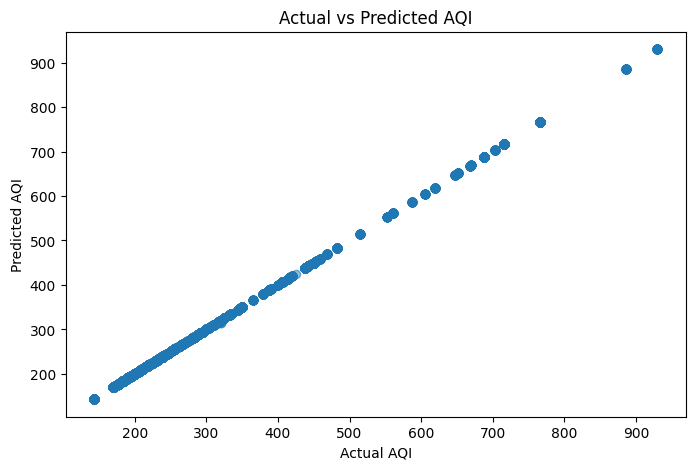

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")

plt.show()

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

importance

,0
pm10,0.951509
pm25,0.045006
so2,0.001216
pressure,0.000783
humidity,0.000443
no2,0.000341
o3,0.000267
co,0.000250
temperature,0.000167
wind_speed,0.000020


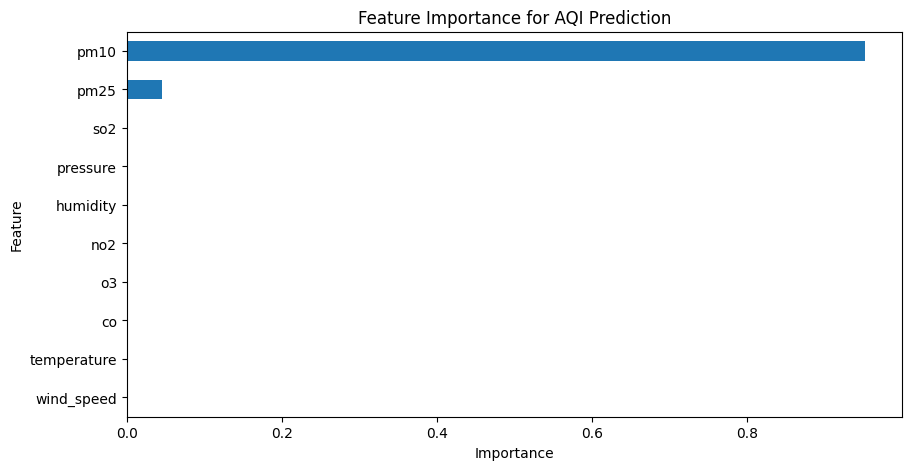

In [ ]:
plt.figure(figsize=(10, 5))

importance.sort_values().plot(kind='barh')

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance for AQI Prediction")

plt.show()

In [ ]:
new_data = pd.DataFrame({
    'pm25': [80],
    'pm10': [150],
    'no2': [40],
    'so2': [10],
    'o3': [30],
    'co': [1.2],
    'temperature': [30],
    'humidity': [60],
    'pressure': [1005],
    'wind_speed': [3]
})

In [ ]:
predicted_aqi = model.predict(new_data)

print("Predicted AQI:", predicted_aqi[0])

Predicted AQI: 201.57


In [ ]:
final_results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Value': [mae, mse, rmse, r2]
})

final_results

,Metric,Value
0,MAE,0.000599
1,MSE,0.003541
2,RMSE,0.059503
3,R² Score,1.000000


In [ ]:
prediction_results = pd.DataFrame({
    'Actual AQI': y_test.values,
    'Predicted AQI': y_pred
})

prediction_results.to_csv(
    'AQI_prediction_results.csv',
    index=False
)

print("Prediction results saved successfully.")

Prediction results saved successfully.


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': importance.index,
    'Importance': importance.values
})

feature_importance.to_csv(
    'AQI_feature_importance.csv',
    index=False
)

print("Feature importance saved successfully.")

Feature importance saved successfully.


In [ ]:
from google.colab import files

files.download('AQI_prediction_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('AQI_feature_importance.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
final_results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Value': [mae, mse, rmse, r2]
})

final_results

,Metric,Value
0,MAE,0.000599
1,MSE,0.003541
2,RMSE,0.059503
3,R² Score,1.000000


In [ ]:
feature_importance_final = pd.DataFrame({
    'Feature': importance.index,
    'Importance': importance.values
})

feature_importance_final

,Feature,Importance
0,pm10,0.951509
1,pm25,0.045006
2,so2,0.001216
3,pressure,0.000783
4,humidity,0.000443
5,no2,0.000341
6,o3,0.000267
7,co,0.000250
8,temperature,0.000167
9,wind_speed,0.000020


In [ ]:
most_important_feature = importance.idxmax()
highest_importance = importance.max()

print("Most important feature:", most_important_feature)
print("Importance value:", highest_importance)


Most important feature: pm10
Importance value: 0.9515090566146515


In [ ]:
new_data = pd.DataFrame({
    'pm25': [80],
    'pm10': [150],
    'no2': [40],
    'so2': [10],
    'o3': [30],
    'co': [1.2],
    'temperature': [30],
    'humidity': [60],
    'pressure': [1005],
    'wind_speed': [3]
})

In [ ]:
predicted_aqi = model.predict(new_data)

print("Predicted AQI:", predicted_aqi[0])

Predicted AQI: 201.57


In [ ]:
error = y_test - y_pred

error_df = pd.DataFrame({
    'Actual AQI': y_test.values,
    'Predicted AQI': y_pred,
    'Error': error
})

print(error_df.head(10))
print("\nMean Error:", error.mean())
print("Maximum Absolute Error:", np.abs(error).max())

         Actual AQI  Predicted AQI  Error
75888         208.0          208.0    0.0
192740        304.0          304.0    0.0
2090250       176.0          176.0    0.0
885527        287.0          287.0    0.0
2903689       181.0          181.0    0.0
1496574       263.0          263.0    0.0
2467048       193.0          193.0    0.0
71445         251.0          251.0    0.0
621962        688.0          688.0    0.0
2409149       199.0          199.0    0.0

Mean Error: 0.0005909999999999996
Maximum Absolute Error: 5.949999999999989


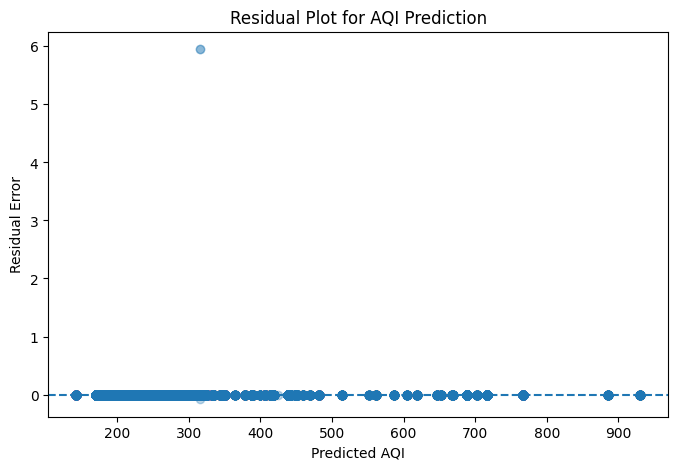

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(y_pred, y_test - y_pred, alpha=0.3)

plt.axhline(0, linestyle='--')

plt.xlabel("Predicted AQI")
plt.ylabel("Residual Error")
plt.title("Residual Plot for AQI Prediction")

plt.show()

In [ ]:
print("Model Performance")
print("------------------")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

Model Performance
------------------
MAE  : 0.000599
MSE  : 0.003541
RMSE : 0.059503
R²   : 1.000000


In [ ]:
import joblib

joblib.dump(model, 'AQI_RandomForest_Model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
new_prediction = model.predict(new_data)

print("Predicted AQI:", new_prediction[0])

Predicted AQI: 201.57


In [ ]:
prediction_result = pd.DataFrame({
    'Predicted AQI': new_prediction
})

prediction_result

,Predicted AQI
0,201.57


In [ ]:
prediction_result.to_csv(
    'AQI_new_prediction.csv',
    index=False
)

print("Prediction saved successfully!")

Prediction saved successfully!


In [ ]:
from google.colab import files

files.download('AQI_RandomForest_Model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('AQI_new_prediction.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


new_data = pd.DataFrame({
    'pm25': [200],
    'pm10': [300],
    'no2': [30],
    'so2': [8],
    'o3': [25],
    'co': [10],
    'temperature': [30],
    'humidity': [60],
    'pressure': [985],
    'wind_speed': [0.4]
})

predicted_aqi = model.predict(new_data)

print("Predicted AQI:", round(predicted_aqi[0], 2))

Predicted AQI: 302.0


In [ ]:


correlation = data_model.corr(numeric_only=True)['aqi'].sort_values(ascending=False)

print("Correlation of features with AQI:")
print(correlation)

Correlation of features with AQI:
aqi            1.000000
pm10           0.983945
pm25           0.756625
co             0.517334
humidity       0.336988
so2            0.160439
no2            0.127900
pressure      -0.031255
wind_speed    -0.154334
o3            -0.240478
temperature   -0.280269
Name: aqi, dtype: float64


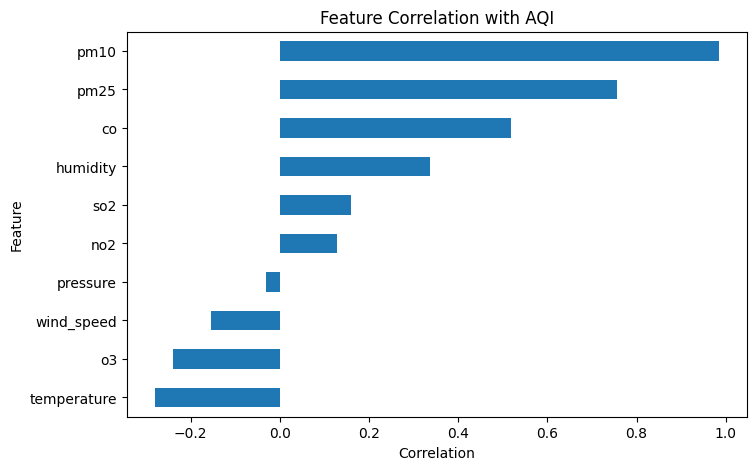

In [ ]:

import matplotlib.pyplot as plt

correlation.drop('aqi').sort_values().plot(kind='barh', figsize=(8,5))

plt.title("Feature Correlation with AQI")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.show()

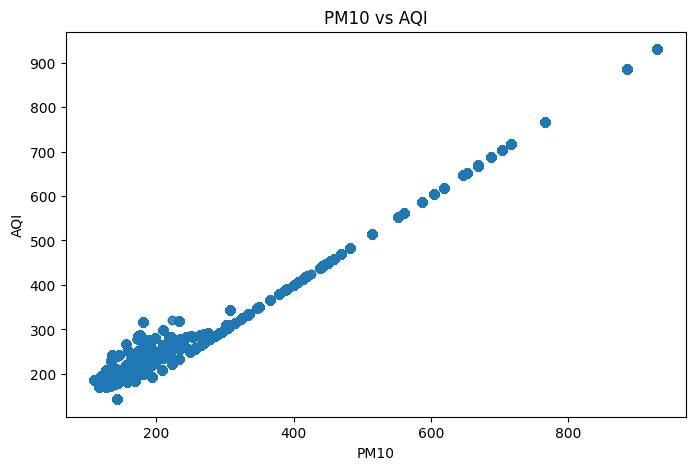

In [ ]:

plt.figure(figsize=(8,5))

plt.scatter(data_model['pm10'], data_model['aqi'], alpha=0.3)

plt.xlabel('PM10')
plt.ylabel('AQI')
plt.title('PM10 vs AQI')

plt.show()

In [ ]:

print("PM10 correlation with AQI:",
      data_model['pm10'].corr(data_model['aqi']))

print("PM2.5 correlation with AQI:",
      data_model['pm25'].corr(data_model['aqi']))

PM10 correlation with AQI: 0.9839446667741555
PM2.5 correlation with AQI: 0.756624964569307


Mean Error: 0.0005909999999999996
Maximum Error: 5.949999999999989
Minimum Error: -0.07999999999998408


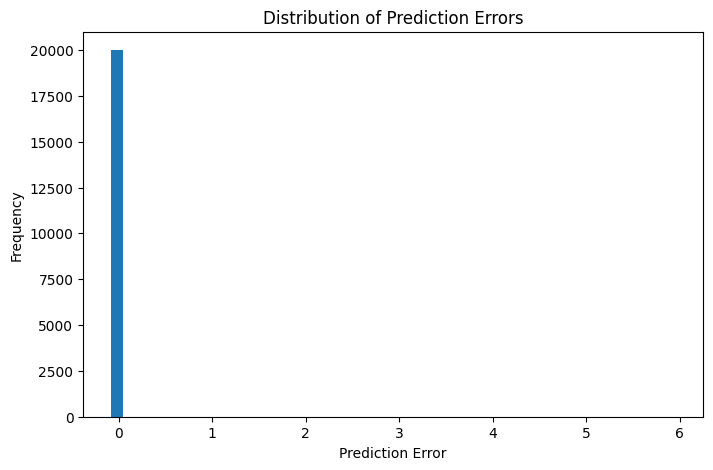

In [ ]:

errors = y_test - y_pred

print("Mean Error:", errors.mean())
print("Maximum Error:", errors.max())
print("Minimum Error:", errors.min())

plt.figure(figsize=(8,5))

plt.hist(errors, bins=50)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.show()

In [ ]:


print("Model: Random Forest Regressor")
print("Dataset Size Used: 100,000 records")
print("Training Records: 80,000")
print("Testing Records: 20,000")
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

Model: Random Forest Regressor
Dataset Size Used: 100,000 records
Training Records: 80,000
Testing Records: 20,000
MAE  : 0.000599
MSE  : 0.003541
RMSE : 0.059503
R²   : 1.000000


Predictive Modelling / KDD Workflow
Problem Identification → Data Collection → Data Understanding → Data Preprocessing → Feature Selection → Train-Test Split → Model Development → Prediction → Model Evaluation → Interpretation → New AQI Prediction

In [ ]:

import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def get_aqi_category(aqi):

    if aqi <= 50:
        return "Good", "Air quality is satisfactory."
    elif aqi <= 100:
        return "Satisfactory", "Air quality is acceptable."
    elif aqi <= 200:
        return "Moderate", "Sensitive groups should take care."
    elif aqi <= 300:
        return "Poor", "Health effects may occur."
    elif aqi <= 400:
        return "Very Poor", "Health effects are more likely."
    else:
        return "Severe", "Health alert: serious health effects possible."


def predict_aqi(
    pm25,
    pm10,
    no2,
    so2,
    o3,
    co,
    temperature,
    humidity,
    pressure,
    wind_speed
):

    try:


        new_data = pd.DataFrame({
            "pm25": [float(pm25)],
            "pm10": [float(pm10)],
            "no2": [float(no2)],
            "so2": [float(so2)],
            "o3": [float(o3)],
            "co": [float(co)],
            "temperature": [float(temperature)],
            "humidity": [float(humidity)],
            "pressure": [float(pressure)],
            "wind_speed": [float(wind_speed)]
        })

        predicted_aqi = float(model.predict(new_data)[0])

        predicted_aqi = max(0, predicted_aqi)

        category, message = get_aqi_category(predicted_aqi)

        if predicted_aqi <= 100:
            flag = "LOW HEALTH RISK"
        elif predicted_aqi <= 200:
            flag = "MODERATE HEALTH RISK"
        elif predicted_aqi <= 300:
            flag = "HIGH HEALTH RISK"
        else:
            flag = "VERY HIGH HEALTH RISK"

        if predicted_aqi <= 100:
            color = "#16a34a"
        elif predicted_aqi <= 200:
            color = "#eab308"
        elif predicted_aqi <= 300:
            color = "#f97316"
        else:
            color = "#dc2626"

        result_html = f"""
        <div style="
            background: linear-gradient(135deg,#eff6ff,#eef2ff);
            border:1px solid #bfdbfe;
            border-radius:18px;
            padding:28px;
            text-align:center;
            box-shadow:0 5px 18px rgba(0,0,0,0.08);
        ">

            <div style="
                color:#1d4ed8;
                font-size:15px;
                font-weight:700;
                letter-spacing:1px;
            ">
                PREDICTED AIR QUALITY INDEX
            </div>

            <div style="
                color:#111827;
                font-size:52px;
                font-weight:800;
                margin:8px 0;
            ">
                {predicted_aqi:.2f}
            </div>

            <div style="
                display:inline-block;
                background:{color};
                color:white;
                padding:8px 22px;
                border-radius:25px;
                font-size:16px;
                font-weight:700;
            ">
                {category}
            </div>

            <div style="
                color:#4b5563;
                margin-top:14px;
                font-size:13px;
            ">
                {message}
            </div>

            <div style="
                margin-top:12px;
                color:{color};
                font-weight:700;
                font-size:13px;
            ">
                ⚠ {flag}
            </div>

        </div>
        """

        fig, ax = plt.subplots(figsize=(7, 4))

        ranges = [
            ("Good", 0, 50),
            ("Satisfactory", 51, 100),
            ("Moderate", 101, 200),
            ("Poor", 201, 300),
            ("Very Poor", 301, 400),
            ("Severe", 401, 500)
        ]

        colors = [
            "#22c55e",
            "#84cc16",
            "#eab308",
            "#f97316",
            "#ef4444",
            "#991b1b"
        ]

        for i, ((name, low, high), c) in enumerate(zip(ranges, colors)):
            ax.barh(
                i,
                high - low,
                left=low,
                color=c,
                height=0.55,
                alpha=0.85
            )
            ax.text(
                (low + high) / 2,
                i,
                name,
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color="white"
            )

        ax.axvline(
            predicted_aqi,
            linewidth=3,
            color="black",
            label=f"Predicted AQI = {predicted_aqi:.2f}"
        )

        ax.set_yticks([])
        ax.set_xlabel("AQI Value")
        ax.set_title(
            "AQI Category Reference",
            fontsize=13,
            fontweight="bold"
        )

        ax.set_xlim(0, 500)
        ax.legend(loc="upper right")

        plt.tight_layout()

        return result_html, fig

    except Exception as e:

        return f"""
        <div style="
            background:#fef2f2;
            border:1px solid #fecaca;
            color:#991b1b;
            padding:20px;
            border-radius:12px;
        ">
            <b>Prediction Error</b><br><br>
            {str(e)}
        </div>
        """, None



def clear_all():

    return (
        200,
        300,
        30,
        8,
        25,
        10,
        30,
        60,
        985,
        0.4,
        "",
        None
    )




css = """


.gradio-container {
    max-width: 1400px !important;
    margin: auto !important;
    background: #f4f7fb !important;
    color: #1f2937 !important;
    font-family: "Segoe UI", Arial, sans-serif !important;
}



.header-box {
    background: linear-gradient(
        135deg,
        #2563eb,
        #4f46e5
    ) !important;

    padding: 28px !important;
    border-radius: 18px !important;
    text-align: center !important;

    margin-bottom: 25px !important;

    box-shadow:
        0 8px 25px rgba(37,99,235,0.20) !important;
}

.header-box h1 {
    color: white !important;
    font-size: 32px !important;
    font-weight: 800 !important;
    margin: 0 !important;
}

.header-box p {
    color: #e5e7eb !important;
    font-size: 13px !important;
    margin: 7px 0 !important;
}



.section-title {
    color: #111827 !important;
    font-size: 19px !important;
    font-weight: 700 !important;
}



.card {
    background: white !important;

    border: 1px solid #e5e7eb !important;

    border-radius: 16px !important;

    padding: 20px !important;

    box-shadow:
        0 4px 15px rgba(15,23,42,0.06) !important;
}



label,
label span,
.gr-form label,
.gr-form label span {

    color: #1f2937 !important;

    font-weight: 600 !important;
}




input,
textarea,
select {

    background: white !important;

    color: #111827 !important;

    border: 1px solid #cbd5e1 !important;

    border-radius: 8px !important;
}


input:focus,
textarea:focus,
select:focus {

    border-color: #2563eb !important;

    box-shadow:
        0 0 0 2px rgba(37,99,235,0.15) !important;
}




input[type="number"],
input[type="text"] {

    color: #111827 !important;

    background: #ffffff !important;
}



button {

    border-radius: 9px !important;

    font-weight: 700 !important;
}


/* Prediction button */

.predict-btn {

    background:
        linear-gradient(
            135deg,
            #2563eb,
            #4f46e5
        ) !important;

    color: white !important;

    border: none !important;

    font-size: 15px !important;
}


.predict-btn:hover {

    opacity: 0.90 !important;
}


/* Clear button */

.clear-btn {

    background: white !important;

    color: #374151 !important;

    border: 1px solid #cbd5e1 !important;
}




.info-box {

    background: white !important;

    border: 1px solid #e5e7eb !important;

    border-radius: 14px !important;

    padding: 18px !important;

    color: #374151 !important;

    box-shadow:
        0 4px 12px rgba(15,23,42,0.05) !important;
}


.info-box h3 {

    color: #111827 !important;
}


.info-box p {

    color: #4b5563 !important;

    line-height: 1.6 !important;
}



.gr-markdown,
.gr-markdown p,
.gr-markdown li {

    color: #374151 !important;
}



.footer {

    color: #64748b !important;

    text-align: center !important;

    font-size: 12px !important;

    padding: 20px !important;
}



.disclaimer {

    background: #fff7ed !important;

    border-left: 5px solid #f59e0b !important;

    padding: 14px 18px !important;

    border-radius: 8px !important;

    color: #7c2d12 !important;

    font-size: 12px !important;

}



@media (max-width: 900px) {

    .header-box h1 {
        font-size: 24px !important;
    }

}
"""



with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="indigo",
        neutral_hue="slate"
    ),
    css=css,
    title="AQI Prediction System"
) as demo:



    gr.HTML("""
    <div class="header-box">

        <h1>🌍 Air Quality Index Prediction System</h1>

        <p>
            Machine Learning Based AQI Prediction Using
            Environmental & Meteorological Factors
        </p>

        <p>
            Random Forest Regression &nbsp;|&nbsp;
            Predictive Analytics &nbsp;|&nbsp;
            Environmental Intelligence
        </p>

    </div>
    """)




    with gr.Row():


        with gr.Column(scale=1):

            gr.Markdown(
                "### 🌿 Environmental Parameters",
                elem_classes="section-title"
            )

            with gr.Group(elem_classes="card"):

                pm25 = gr.Number(
                    label="PM2.5 (µg/m³)",
                    value=200
                )

                pm10 = gr.Number(
                    label="PM10 (µg/m³)",
                    value=300
                )

                no2 = gr.Number(
                    label="NO₂ (µg/m³)",
                    value=30
                )

                so2 = gr.Number(
                    label="SO₂ (µg/m³)",
                    value=8
                )

                o3 = gr.Number(
                    label="O₃ (µg/m³)",
                    value=25
                )

                co = gr.Number(
                    label="CO (mg/m³)",
                    value=10
                )

                temperature = gr.Number(
                    label="Temperature (°C)",
                    value=30
                )

                humidity = gr.Number(
                    label="Humidity (%)",
                    value=60
                )

                pressure = gr.Number(
                    label="Atmospheric Pressure",
                    value=985
                )

                wind_speed = gr.Number(
                    label="Wind Speed",
                    value=0.4
                )




            with gr.Row():

                clear_btn = gr.Button(
                    "↻ Clear",
                    elem_classes="clear-btn"
                )

                predict_btn = gr.Button(
                    "🔮 Predict AQI",
                    elem_classes="predict-btn",
                    variant="primary"
                )




        with gr.Column(scale=1):

            gr.Markdown(
                "### 📊 Prediction Result",
                elem_classes="section-title"
            )

            prediction_output = gr.HTML(
                value="""
                <div class="card"
                     style="text-align:center;padding:45px;">

                    <div style="
                        color:#64748b;
                        font-size:16px;
                    ">
                        Enter environmental values
                        and click <b>Predict AQI</b>
                    </div>

                </div>
                """
            )


            gr.Markdown(
                "### 📈 AQI Category Reference",
                elem_classes="section-title"
            )

            chart_output = gr.Plot(
                show_label=False
            )



    gr.Markdown(
        "### 🤖 About the Predictive Model",
        elem_classes="section-title"
    )

    gr.HTML("""
    <div class="info-box">

        <h3>Random Forest Regression</h3>

        <p>
        This system uses a trained Random Forest Regression model
        to estimate the Air Quality Index (AQI) from environmental
        pollutant concentrations and meteorological conditions.
        </p>

        <table style="
            width:100%;
            border-collapse:collapse;
            margin-top:12px;
        ">

            <tr>
                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                    font-weight:600;
                ">
                    Algorithm
                </td>

                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                ">
                    Random Forest Regressor
                </td>
            </tr>

            <tr>
                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                    font-weight:600;
                ">
                    Input Features
                </td>

                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                ">
                    10 Environmental & Meteorological Variables
                </td>
            </tr>

            <tr>
                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                    font-weight:600;
                ">
                    Training Data
                </td>

                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                ">
                    80,000 records
                </td>
            </tr>

            <tr>
                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                    font-weight:600;
                ">
                    Testing Data
                </td>

                <td style="
                    padding:9px;
                    border-bottom:1px solid #e5e7eb;
                ">
                    20,000 records
                </td>
            </tr>

            <tr>
                <td style="
                    padding:9px;
                    font-weight:600;
                ">
                    Purpose
                </td>

                <td style="
                    padding:9px;
                ">
                    AQI Prediction & Air Quality Assessment
                </td>
            </tr>

        </table>

    </div>
    """)




    gr.HTML("""
    <div class="disclaimer">

        ⚠️ <b>Academic Project Disclaimer:</b>

        This system is developed for educational and
        demonstration purposes as part of a Predictive Analytics
        project. The predicted AQI should be interpreted as a
        machine-learning estimate and not as an official
        environmental monitoring measurement.

    </div>
    """)




    gr.HTML("""
    <div class="footer">

        🌍 Air Quality Index Prediction System
        &nbsp; | &nbsp;
        Random Forest Regression
        &nbsp; | &nbsp;
        Predictive Analytics

    </div>
    """)



    predict_btn.click(
        fn=predict_aqi,

        inputs=[
            pm25,
            pm10,
            no2,
            so2,
            o3,
            co,
            temperature,
            humidity,
            pressure,
            wind_speed
        ],

        outputs=[
            prediction_output,
            chart_output
        ]
    )


    clear_btn.click(
        fn=clear_all,

        inputs=[],

        outputs=[
            pm25,
            pm10,
            no2,
            so2,
            o3,
            co,
            temperature,
            humidity,
            pressure,
            wind_speed,
            prediction_output,
            chart_output
        ]
    )




demo.launch()

/tmp/ipykernel_591/558559911.py:483: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9be09cb3b1e06baea1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


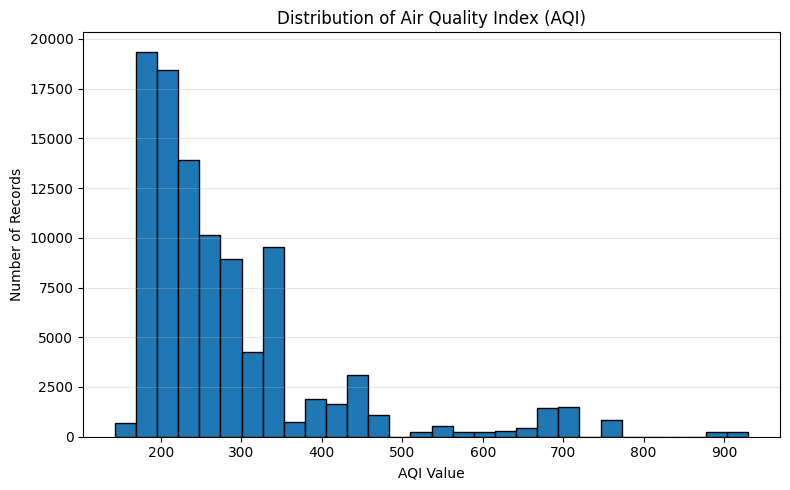

In [ ]:



import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(data_model['aqi'], bins=30, edgecolor='black')

plt.title('Distribution of Air Quality Index (AQI)')
plt.xlabel('AQI Value')
plt.ylabel('Number of Records')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

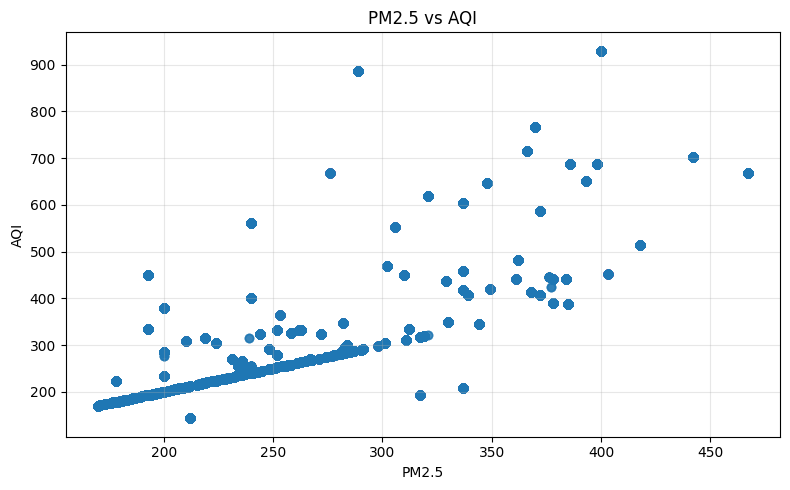

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(
    data_model['pm25'],
    data_model['aqi'],
    alpha=0.3
)

plt.xlabel('PM2.5')
plt.ylabel('AQI')
plt.title('PM2.5 vs AQI')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


In [ ]:
print(model)
print("\nModel parameters:")
print(model.get_params())

RandomForestRegressor(n_jobs=-1, random_state=42)

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
